# Module 3 — IBNR Reserving (v2, corrigé)

**Correction par rapport à la v1** : la CAS Loss Reserve Database fournit un **carré complet**
(100 lignes pour 10 AY × 10 lags), pas un triangle (55 lignes). Le carré contient, pour
chaque année de survenance, le développement réel observé jusqu'au lag 10 — y compris
des lags "futurs" par rapport à la diagonale d'évaluation.

**Implication** : pour calculer Chain Ladder/Mack/BF/Bootstrap, on doit restreindre les
données au **triangle haut-gauche** (la diagonale d'évaluation et ce qui est avant).
Le reste du carré est conservé pour un **backtest** : comparer l'ultime projeté à
l'ultime réellement observé.

In [1]:
# ============================================================
# SETUP
# ============================================================
!pip install chainladder -q

import pandas as pd
import numpy as np
import chainladder as cl
import matplotlib.pyplot as plt
import json
import warnings
warnings.filterwarnings('ignore')

print(f"chainladder version : {cl.__version__}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 24.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 151.9/151.9 kB 3.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 2.3.3 which is incompatible.
chainladder version : 0.9.2


## Bloc 1 — Chargement des données CAS

In [2]:
URL = "https://www.casact.org/sites/default/files/2021-04/ppauto_pos.csv"

df = pd.read_csv(URL)
print(f"Lignes : {len(df)} | Colonnes : {df.shape[1]}")
print(f"Compagnies (GRCODE) : {df['GRCODE'].nunique()}")

# Vérifier le suffixe réel des colonnes nettes (peut être _B, _C ou _N selon le fichier)
loss_cols = [c for c in df.columns if 'Loss' in c or 'Prem' in c]
print("\nColonnes de pertes/primes disponibles :")
print(loss_cols)

Lignes : 14600 | Colonnes : 13
Compagnies (GRCODE) : 146

Colonnes de pertes/primes disponibles :
['IncurLoss_B', 'CumPaidLoss_B', 'BulkLoss_B', 'EarnedPremDIR_B', 'EarnedPremCeded_B', 'EarnedPremNet_B']


> **Adapter le suffixe** : la suite du notebook utilise le suffixe `_B`
> (`CumPaidLoss_B`, `IncurLoss_B`, `EarnedPremNet_B`). Si la liste affichée
> ci-dessus montre un autre suffixe (`_C`, `_D`, `_N`...), remplace `SUFFIX`
> ci-dessous en conséquence — tout le reste du notebook s'adapte automatiquement.

In [3]:
SUFFIX = "_B"  # <-- ajuster si besoin selon la sortie de la cellule précédente

COL_PAID = f"CumPaidLoss{SUFFIX}"
COL_INCURRED = f"IncurLoss{SUFFIX}"
COL_PREMIUM = f"EarnedPremNet{SUFFIX}"

print(f"Colonnes utilisées : {COL_PAID}, {COL_INCURRED}, {COL_PREMIUM}")

Colonnes utilisées : CumPaidLoss_B, IncurLoss_B, EarnedPremNet_B


## Bloc 2 — Sélection d'une compagnie

In [4]:
volume = (
    df[df['DevelopmentLag'] == 1]
    .groupby('GRCODE')[COL_PREMIUM]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 compagnies par volume de prime :")
print(volume.head(10))

GRCODE = volume.index[3]  # 4e plus gros volume -- ajuster si besoin
company_name = df[df['GRCODE'] == GRCODE]['GRNAME'].iloc[0]
print(f"\nCompagnie sélectionnée : GRCODE={GRCODE} | {company_name}")

Top 10 compagnies par volume de prime :
GRCODE
1767    117655840
2003     17482366
4839      4078168
7080      1825656
3240      1408635
1090      1295968
388       1270861
6947      1088573
620        589907
671        439679
Name: EarnedPremNet_B, dtype: int64

Compagnie sélectionnée : GRCODE=7080 | New Jersey Manufacturers Grp


## Bloc 3 — Isolation du carré complet et filtrage du triangle haut-gauche

**Pourquoi 100 lignes et pas 55 ?** La CAS Loss Reserve Database fournit, pour chaque
(année de survenance, lag de développement), la valeur **réellement observée** —
y compris pour les combinaisons situées *après* la diagonale d'évaluation. C'est ce
qui permet de backtester une méthode de réserve contre la réalité.

**Triangle haut-gauche ("connu")** : on ne garde que les cellules où
`AccidentYear + DevelopmentLag - 1 <= max(AccidentYear)` — c'est-à-dire
ce qui était observable à la date d'évaluation du triangle. C'est sur ce sous-ensemble
(55 lignes pour 10 AY) que Chain Ladder/Mack/BF/Bootstrap doivent être ajustés.

In [5]:
df_company = df[df['GRCODE'] == GRCODE].copy()

n_ay = df_company['AccidentYear'].nunique()
n_dev = df_company['DevelopmentLag'].nunique()
max_ay = df_company['AccidentYear'].max()
min_ay = df_company['AccidentYear'].min()

print(f"Années de survenance : {n_ay} ({min_ay}-{max_ay}) | Lags de développement : {n_dev}")
print(f"Nb de lignes (carré complet) : {len(df_company)} (= {n_ay} x {n_dev})")

neg = (df_company[COL_PAID] < 0).sum()
print(f"Valeurs négatives {COL_PAID} : {neg}")

# --- Filtrage : triangle haut-gauche uniquement ---
df_triangle = df_company[
    df_company['DevelopmentLag'] <= (max_ay - df_company['AccidentYear'] + 1)
].copy()

expected = n_ay * (n_ay + 1) // 2
print(f"\nNb de lignes (triangle haut-gauche) : {len(df_triangle)} (attendu : {expected})")
assert len(df_triangle) == expected, "Le filtrage n'a pas produit un triangle complet -- vérifier les données."

Années de survenance : 10 (1988-1997) | Lags de développement : 10
Nb de lignes (carré complet) : 100 (= 10 x 10)
Valeurs négatives CumPaidLoss_B : 0

Nb de lignes (triangle haut-gauche) : 55 (attendu : 55)


## Bloc 4 — Construction du triangle

In [6]:
triangle = cl.Triangle(
    data=df_triangle,
    origin='AccidentYear',
    development='DevelopmentYear',
    columns=[COL_PAID, COL_INCURRED, COL_PREMIUM],
    cumulative=True
)

print(triangle)
print(f"\nForme du triangle : {triangle.shape}")
print(f"Périodes de survenance : {triangle.origin.min()} -> {triangle.origin.max()}")

# Vérification : la forme doit être (1, 3, n_ay, n_ay) -- carrée, pas 19x19
assert triangle.shape[-1] == n_ay, f"Triangle mal formé : {triangle.shape[-1]} colonnes attendues={n_ay}"

                                         Triangle Summary
Valuation:                                        1997-12
Grain:                                               OYDY
Shape:                                     (1, 3, 10, 10)
Index:                                            [Total]
Columns:    [CumPaidLoss_B, IncurLoss_B, EarnedPremNet_B]

Forme du triangle : (1, 3, 10, 10)
Périodes de survenance : 1988 -> 1997


In [7]:
paid = triangle[COL_PAID]
paid_df = paid.to_frame(origin_as_datetime=False)
print(f"Triangle des paiements cumulés ({COL_PAID}) :")
paid_df.round(0)

Triangle des paiements cumulés (CumPaidLoss_B) :


,12,24,36,48,60,72,84,96,108,120
1988,19101.0,37997.0,51318.0,62647.0,71994.0,76198.0,78446.0,79251.0,80841.0,81094.0
1989,21116.0,40976.0,56004.0,68769.0,79194.0,86686.0,89600.0,90985.0,92157.0,NaN
1990,20624.0,39858.0,54786.0,72060.0,85890.0,95050.0,98737.0,100024.0,NaN,NaN
1991,20864.0,40838.0,58340.0,79629.0,100485.0,109594.0,112668.0,NaN,NaN,NaN
1992,23616.0,45974.0,66394.0,90270.0,112385.0,120640.0,NaN,NaN,NaN,NaN
1993,26709.0,53911.0,77370.0,107698.0,131582.0,NaN,NaN,NaN,NaN,NaN
1994,28869.0,58416.0,85436.0,113546.0,NaN,NaN,NaN,NaN,NaN,NaN
1995,32084.0,69454.0,99874.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1996,40328.0,80683.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1997,46599.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Bloc 5 — Chain Ladder

In [8]:
cl_model = cl.Chainladder().fit(paid)

print("Facteurs de développement (LDF) :")
print(cl_model.ldf_.to_frame(origin_as_datetime=False).round(4))

print("\nFacteurs cumulés (CDF) :")
print(cl_model.cdf_.to_frame(origin_as_datetime=False).round(4))

# Sanity check : les CDF doivent décroître de manière monotone vers 1
cdf_vals = cl_model.cdf_.to_frame(origin_as_datetime=False).iloc[0].dropna().values
assert all(cdf_vals[i] >= cdf_vals[i+1] for i in range(len(cdf_vals)-1)), "CDF non monotone -- vérifier le triangle"
assert abs(cdf_vals[-1] - 1.0) < 1e-6, "Le dernier CDF doit être 1.0"

Facteurs de développement (LDF) :
        12-24   24-36   36-48   48-60   60-72   72-84  84-96  96-108  108-120  \
(All)  2.0064  1.4184  1.3224  1.2088  1.0849  1.0324  1.013  1.0162   1.0031   

       120-132  132-144  
(All)      1.0      1.0  

Facteurs cumulés (CDF) :
       12-Ult  24-Ult  36-Ult  48-Ult  60-Ult  72-Ult  84-Ult  96-Ult  \
(All)  5.2623  2.6228  1.8491  1.3983  1.1568  1.0662  1.0327  1.0194   

       108-Ult  120-Ult  132-Ult  
(All)   1.0031      1.0      1.0  


In [9]:
ultimate_cl = cl_model.ultimate_.to_frame(origin_as_datetime=False)
ibnr_cl = cl_model.ibnr_.to_frame(origin_as_datetime=False)

cl_summary = pd.DataFrame({
    'paid_to_date': paid.latest_diagonal.to_frame(origin_as_datetime=False).iloc[:, 0],
    'ultimate': ultimate_cl.iloc[:, 0],
    'reserve_ibnr': ibnr_cl.iloc[:, 0],
})
cl_summary['reserve_pct'] = (cl_summary['reserve_ibnr'] / cl_summary['ultimate'] * 100).round(1)

print("Résultats Chain Ladder par année de survenance :")
print(cl_summary.round(0))
print(f"\n>>> Réserve IBNR totale (Chain Ladder) : {cl_summary['reserve_ibnr'].sum():,.0f}")
print(f">>> Ultime total : {cl_summary['ultimate'].sum():,.0f}")

assert cl_summary['reserve_ibnr'].sum() > 0, "Réserve totale nulle -- le triangle est probablement mal construit"

Résultats Chain Ladder par année de survenance :
      paid_to_date  ultimate  reserve_ibnr  reserve_pct
1988       81094.0   81094.0           NaN          NaN
1989       92157.0   92445.0         288.0          0.0
1990      100024.0  101965.0        1941.0          2.0
1991      112668.0  116351.0        3683.0          3.0
1992      120640.0  128625.0        7985.0          6.0
1993      131582.0  152209.0       20627.0         14.0
1994      113546.0  158773.0       45227.0         28.0
1995       99874.0  184681.0       84807.0         46.0
1996       80683.0  211617.0      130934.0         62.0
1997       46599.0  245219.0      198620.0         81.0

>>> Réserve IBNR totale (Chain Ladder) : 494,113
>>> Ultime total : 1,472,980


## Bloc 6 — Mack Chain Ladder

In [10]:
mack_model = cl.MackChainladder().fit(paid)

mack_summary = pd.DataFrame({
    'ultimate': mack_model.ultimate_.to_frame().iloc[:, 0],
    'reserve_ibnr': mack_model.ibnr_.to_frame().iloc[:, 0],
    'std_error': mack_model.mack_std_err_.to_frame().iloc[:, 0],
})

mack_summary['cv'] = (
    mack_summary['std_error'] / mack_summary['reserve_ibnr']
).round(3)

mack_summary['reserve_95_lower'] = (
    mack_summary['reserve_ibnr'] - 1.96 * mack_summary['std_error']
).clip(lower=0)

mack_summary['reserve_95_upper'] = (
    mack_summary['reserve_ibnr'] + 1.96 * mack_summary['std_error']
)

print(mack_summary.round(0))

total_reserve_mack = float(mack_summary['reserve_ibnr'].sum())
total_se_mack = float(mack_model.total_mack_std_err_)

print(f"\n>>> Réserve totale (Mack) : {total_reserve_mack:,.0f}")
print(f">>> Écart-type total : {total_se_mack:,.0f}")
print(f">>> CV total : {total_se_mack/total_reserve_mack:.1%}")

            ultimate  reserve_ibnr  std_error  cv  reserve_95_lower  \
1988-01-01   81094.0           NaN        NaN NaN               NaN   
1989-01-01   92445.0         288.0        NaN NaN               NaN   
1990-01-01  101965.0        1941.0        NaN NaN               NaN   
1991-01-01  116351.0        3683.0        NaN NaN               NaN   
1992-01-01  128625.0        7985.0        NaN NaN               NaN   
1993-01-01  152209.0       20627.0        NaN NaN               NaN   
1994-01-01  158773.0       45227.0        NaN NaN               NaN   
1995-01-01  184681.0       84807.0        NaN NaN               NaN   
1996-01-01  211617.0      130934.0        NaN NaN               NaN   
1997-01-01  245219.0      198620.0        NaN NaN               NaN   

            reserve_95_upper  
1988-01-01               NaN  
1989-01-01               NaN  
1990-01-01               NaN  
1991-01-01               NaN  
1992-01-01               NaN  
1993-01-01               NaN  
1

TypeError: float() argument must be a string or a real number, not 'DataFrame'

### Diagnostic Mack — résidus standardisés

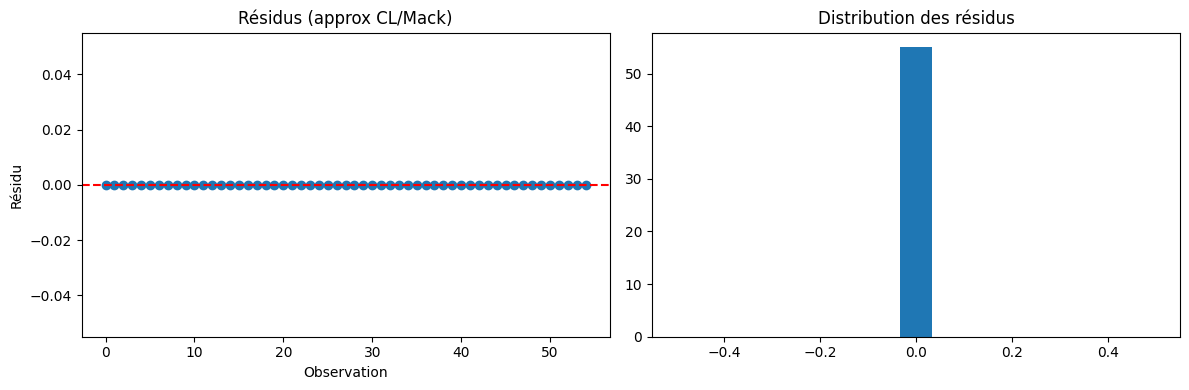

Résidu moyen : 0.000
Résidu std   : 0.000


In [11]:
# valeurs observées
obs = paid.to_frame(origin_as_datetime=False)

# valeurs projetées par Chain Ladder (approx Mack)
dev = mack_model.full_triangle_.to_frame(origin_as_datetime=False)

# résidus bruts
residuals = obs - dev

resid_vals = residuals.values.flatten()
resid_vals = resid_vals[~np.isnan(resid_vals)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(range(len(resid_vals)), resid_vals)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_title("Résidus (approx CL/Mack)")
axes[0].set_xlabel("Observation")
axes[0].set_ylabel("Résidu")

axes[1].hist(resid_vals, bins=15)
axes[1].set_title("Distribution des résidus")

plt.tight_layout()
plt.show()

print(f"Résidu moyen : {resid_vals.mean():.3f}")
print(f"Résidu std   : {resid_vals.std():.3f}")

## Bloc 7 — Bornhuetter-Ferguson

In [12]:
# A priori basé directement sur les diagonales du DataFrame (plus robuste
# que latest_diagonal + isin, qui pose des problèmes d'index)
diag = df_triangle[
    df_triangle['DevelopmentLag'] == (max_ay - df_triangle['AccidentYear'] + 1)
]

mature_years = sorted(df_triangle['AccidentYear'].unique())[:-3]
mature_diag = diag[diag['AccidentYear'].isin(mature_years)]

apriori_lr = mature_diag[COL_INCURRED].sum() / mature_diag[COL_PREMIUM].sum()

print(f"Années matures : {mature_years}")
print(f"Loss ratio a priori : {apriori_lr:.2%}")

# garder 'premium' pour la cellule bf_model suivante
premium = triangle[COL_PREMIUM]

Années matures : [np.int64(1988), np.int64(1989), np.int64(1990), np.int64(1991), np.int64(1992), np.int64(1993), np.int64(1994)]
Loss ratio a priori : 91.34%


In [13]:
bf_model = cl.BornhuetterFerguson(apriori=apriori_lr).fit(
    paid,
    sample_weight=premium.latest_diagonal
)

bf_summary = pd.DataFrame({
    'ultimate_cl': cl_summary['ultimate'],
    'ultimate_bf': bf_model.ultimate_.to_frame(origin_as_datetime=False).iloc[:, 0],
    'reserve_bf': bf_model.ibnr_.to_frame(origin_as_datetime=False).iloc[:, 0],
})

print("Comparaison Chain Ladder vs BF :")
print(bf_summary.round(0))
print(f"\n>>> Réserve totale (BF) : {bf_summary['reserve_bf'].sum():,.0f}")
print(f">>> Réserve totale (Chain Ladder) : {cl_summary['reserve_ibnr'].sum():,.0f}")

Comparaison Chain Ladder vs BF :
      ultimate_cl  ultimate_bf  reserve_bf
1988      81094.0      81094.0         NaN
1989      92445.0      92413.0       256.0
1990     101965.0     101882.0      1858.0
1991     116351.0     116728.0      4060.0
1992     128625.0     130288.0      9648.0
1993     152209.0     153338.0     21756.0
1994     158773.0     163787.0     50241.0
1995     184681.0     206596.0    106722.0
1996     211617.0     239321.0    158638.0
1997     245219.0     285823.0    239224.0

>>> Réserve totale (BF) : 592,404
>>> Réserve totale (Chain Ladder) : 494,113


## Bloc 8 — Bootstrap ODP

In [14]:
N_SIMS = 1000

bootstrap_sampler = cl.BootstrapODPSample(n_sims=N_SIMS, random_state=42)
bootstrap_triangles = bootstrap_sampler.fit_transform(paid)

bootstrap_cl = cl.Chainladder().fit(bootstrap_triangles)

ibnr_dist = bootstrap_cl.ibnr_.sum('origin').to_frame(origin_as_datetime=False)
reserve_samples = ibnr_dist.values.flatten()

print(f"Nombre de simulations : {len(reserve_samples)}")
print(f"Réserve moyenne (Bootstrap) : {reserve_samples.mean():,.0f}")
print(f"Écart-type (Bootstrap)      : {reserve_samples.std():,.0f}")
print(f"\nPercentiles :")
for p in [5, 25, 50, 75, 90, 95, 99]:
    print(f"  P{p:>2} : {np.percentile(reserve_samples, p):,.0f}")

# Sanity check : la moyenne Bootstrap doit être proche de la réserve centrale CL
ecart_pct = abs(reserve_samples.mean() - cl_summary['reserve_ibnr'].sum()) / cl_summary['reserve_ibnr'].sum() * 100
print(f"\nÉcart Bootstrap vs Chain Ladder : {ecart_pct:.1f}% (cible : < 10%)")

Nombre de simulations : 1000
Réserve moyenne (Bootstrap) : 495,454
Écart-type (Bootstrap)      : 28,132

Percentiles :
  P 5 : 452,143
  P25 : 475,727
  P50 : 495,392
  P75 : 513,224
  P90 : 531,935
  P95 : 542,056
  P99 : 566,309

Écart Bootstrap vs Chain Ladder : 0.3% (cible : < 10%)


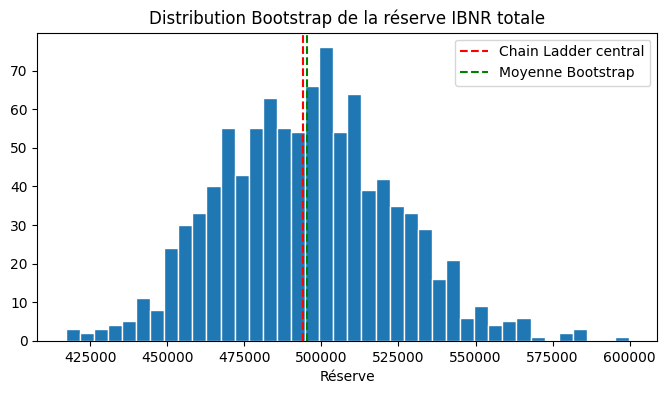

In [15]:
plt.figure(figsize=(8, 4))
plt.hist(reserve_samples, bins=40, edgecolor='white')
plt.axvline(cl_summary['reserve_ibnr'].sum(), color='red', linestyle='--', label='Chain Ladder central')
plt.axvline(reserve_samples.mean(), color='green', linestyle='--', label='Moyenne Bootstrap')
plt.title("Distribution Bootstrap de la réserve IBNR totale")
plt.xlabel("Réserve")
plt.legend()
plt.show()

## Bloc 9 — Backtest : projection vs réalité (bonus actuariel)

On exploite ici la partie du carré complet qu'on n'a **pas** utilisée pour ajuster
les modèles : le paiement cumulé réellement observé au lag 10 pour chaque année de
survenance, c'est-à-dire **l'ultime réel**. On le compare à l'ultime **projeté**
par Chain Ladder à partir du seul triangle haut-gauche.

C'est une validation out-of-sample rarement possible en pratique (il faut attendre
des années pour savoir si une réserve était juste) — ici les données CAS nous
donnent directement la réponse.

In [16]:
# ============================================================
# BLOC 9 — Backtest, sans dépendre de l'index chainladder
# ============================================================
origin_years = sorted(df_triangle['AccidentYear'].unique())

backtest_df = pd.DataFrame({
    'origin_year': origin_years,
    'paid_to_date': paid.latest_diagonal.to_frame(origin_as_datetime=False).values.flatten(),
    'ultimate': cl_model.ultimate_.to_frame(origin_as_datetime=False).values.flatten(),
}).set_index('origin_year')

actual_ultimate_map = (
    df_company[df_company['DevelopmentLag'] == n_dev]
    .set_index('AccidentYear')[COL_PAID]
)

backtest_df['actual_ultimate'] = [actual_ultimate_map.get(y, np.nan) for y in origin_years]
backtest_df['error'] = backtest_df['ultimate'] - backtest_df['actual_ultimate']
backtest_df['error_pct'] = (backtest_df['error'] / backtest_df['actual_ultimate'] * 100).round(1)

print(backtest_df.round(0))

mape = backtest_df['error_pct'].abs().dropna().mean()
print(f"\nMAPE = {mape:.1f}%")

             paid_to_date  ultimate  actual_ultimate   error  error_pct
origin_year                                                            
1988              81094.0   81094.0            81094     0.0        0.0
1989              92157.0   92445.0            92303   142.0        0.0
1990             100024.0  101965.0           101527   438.0        0.0
1991             112668.0  116351.0           114831  1520.0        1.0
1992             120640.0  128625.0           128664   -39.0       -0.0
1993             131582.0  152209.0           149284  2925.0        2.0
1994             113546.0  158773.0           155191  3582.0        2.0
1995              99874.0  184681.0           179647  5034.0        3.0
1996              80683.0  211617.0           215678 -4061.0       -2.0
1997              46599.0  245219.0           241697  3522.0        2.0

MAPE = 1.2%


## Bloc 10 — Tableau comparatif final

In [17]:


# -----------------------------
# EXTRACTION SAFE MACK STD ERROR
# -----------------------------
total_se_mack = mack_model.total_mack_std_err_

# si c'est un DataFrame 1x1 → extraction scalaire
if isinstance(total_se_mack, pd.DataFrame):
    total_se_mack = total_se_mack.values.item()
else:
    total_se_mack = float(total_se_mack)

# -----------------------------
# BUILD COMPARISON TABLE
# -----------------------------
comparison = pd.DataFrame({
    'Méthode': [
        'Chain Ladder',
        'Mack',
        'Bornhuetter-Ferguson',
        'Bootstrap ODP (moyenne)'
    ],
    'Réserve IBNR': [
        cl_summary['reserve_ibnr'].sum(),
        mack_summary['reserve_ibnr'].sum(),
        bf_summary['reserve_bf'].sum(),
        reserve_samples.mean(),
    ],
    'Écart-type / Incertitude': [
        np.nan,
        total_se_mack,
        np.nan,
        reserve_samples.std(),
    ],
})

# -----------------------------
# CLEAN NUMERIC ROUNDING
# -----------------------------
comparison[['Réserve IBNR', 'Écart-type / Incertitude']] = comparison[
    ['Réserve IBNR', 'Écart-type / Incertitude']
].apply(pd.to_numeric, errors='coerce').round(0)

# -----------------------------
# OUTPUT
# -----------------------------
print(comparison)

                   Méthode  Réserve IBNR  Écart-type / Incertitude
0             Chain Ladder      494113.0                       NaN
1                     Mack      494113.0                   29160.0
2     Bornhuetter-Ferguson      592404.0                       NaN
3  Bootstrap ODP (moyenne)      495454.0                   28132.0


### Checklist de validation actuarielle

- [ ] Chain Ladder et Mack donnent **la même réserve centrale** (écart ~0)
- [ ] Les CDF (Bloc 5) décroissent de manière monotone vers 1
- [ ] Les résidus de Mack (Bloc 6) ne montrent pas de tendance forte
- [ ] BF converge vers Chain Ladder sur les années matures
- [ ] La moyenne Bootstrap est proche (±10%) de la réserve centrale Chain Ladder
- [ ] Le CV de Mack est dans une plage réaliste (5%-30% pour de l'auto)
- [ ] **Le MAPE du backtest (Bloc 9) est dans une plage raisonnable (< ~20%)**

## Bloc 11 — Export pour l'intégration FastAPI

In [20]:
# Helper : convertit n'importe quel index Period/Timestamp/int en str JSON-compatible
def to_year_str(idx):
    if hasattr(idx, 'year'):   # Period ou Timestamp
        return str(idx.year)
    return str(int(idx))

# Reconstruction des dicts avec clés string
cl_ultimate_dict   = {to_year_str(k): v for k, v in cl_summary['ultimate'].round(0).items()}
cl_reserve_dict    = {to_year_str(k): v for k, v in cl_summary['reserve_ibnr'].round(0).items()}
bf_reserve_dict    = {to_year_str(k): v for k, v in bf_summary['reserve_bf'].round(0).items()}

mack_by_year_dict  = {
    to_year_str(k): {col: round(v2, 0) for col, v2 in v.items()}
    for k, v in mack_summary[['reserve_ibnr', 'std_error']].to_dict(orient='index').items()
}

backtest_dict = {
    to_year_str(k): {col: round(v2, 2) for col, v2 in v.items()}
    for k, v in backtest_df[['ultimate', 'actual_ultimate', 'error_pct']].to_dict(orient='index').items()
}

export = {
    "company": {
        "grcode": int(GRCODE),
        "name": company_name,
        "line_of_business": "Private Passenger Auto",
    },
    "triangle": {
        "origin_years": [y.year if hasattr(y, 'year') else int(y) for y in paid_df.index],
        "development_lags": list(range(1, n_dev + 1)),
        "cumulative_paid": paid_df.values.tolist(),
    },
    "chain_ladder": {
        "ldf": cl_model.ldf_.to_frame(origin_as_datetime=False).values.flatten().tolist(),
        "cdf": cl_model.cdf_.to_frame(origin_as_datetime=False).values.flatten().tolist(),
        "ultimate_by_year": cl_ultimate_dict,
        "reserve_by_year":  cl_reserve_dict,
        "total_reserve":    float(cl_summary['reserve_ibnr'].sum()),
    },
    "mack": {
        "total_reserve":    float(mack_summary['reserve_ibnr'].sum()),
        "total_std_error":  float(total_se_mack),
        "ci_95_lower":      float(total_reserve_mack - 1.96 * total_se_mack),
        "ci_95_upper":      float(total_reserve_mack + 1.96 * total_se_mack),
        "by_year":          mack_by_year_dict,
    },
    "bornhuetter_ferguson": {
        "apriori_loss_ratio": float(apriori_lr),
        "total_reserve":      float(bf_summary['reserve_bf'].sum()),
        "by_year":            bf_reserve_dict,
    },
    "bootstrap": {
        "n_sims":        N_SIMS,
        "mean_reserve":  float(reserve_samples.mean()),
        "std_reserve":   float(reserve_samples.std()),
        "percentiles":   {str(p): float(np.percentile(reserve_samples, p))
                          for p in [5, 25, 50, 75, 90, 95, 99]},
    },
    "backtest": {
        "mape_pct": float(mape),
        "by_year":  backtest_dict,
    },
}

with open("reserving_meta.json", "w") as f:
    json.dump(export, f, indent=2)

print("Export terminé : reserving_meta.json")
print(json.dumps({k: '...' for k in export.keys()}, indent=2))

Export terminé : reserving_meta.json
{
  "company": "...",
  "triangle": "...",
  "chain_ladder": "...",
  "mack": "...",
  "bornhuetter_ferguson": "...",
  "bootstrap": "...",
  "backtest": "..."
}


In [23]:
# Optionnel : sauvegarder sur Drive
# from google.colab import drive
# drive.mount('/content/drive')
# BASE = '/content/drive/MyDrive/siap'
# import shutil
# shutil.copy('reserving_meta.json', f'{BASE}/data/reserving_meta.json')
# print("Copié sur Drive.")

In [25]:
import pickle

from google.colab import files

files.download("reserving_meta.json")
files.download("models_reserving.pkl")
files.download("triangle_paid.csv")
files.download("cl_summary.csv")
files.download("bootstrap_samples.npy")

# Sauvegarder les modèles
with open("models_reserving.pkl", "wb") as f:
    pickle.dump({
        "cl_model": cl_model,
        "mack_model": mack_model,
        "bf_model": bf_model,
        "bootstrap_sampler": bootstrap_sampler,
    }, f)

# Sauvegarder le triangle paid en CSV
paid.to_frame(origin_as_datetime=False).to_csv("triangle_paid.csv")

# Sauvegarder le résumé Chain Ladder
cl_summary.to_csv("cl_summary.csv")

# Sauvegarder la distribution Bootstrap
import numpy as np
np.save("bootstrap_samples.npy", reserve_samples)

# Télécharger tout
files.download("models_reserving.pkl")
files.download("triangle_paid.csv")
files.download("cl_summary.csv")
files.download("bootstrap_samples.npy")

print("Tous les fichiers téléchargés.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Tous les fichiers téléchargés.
